### DATA ANALYSIS WITH PYTHON INTERNSHIP PROJECT.
### Name of Company: Auspify Technologies
### Name of Intern: Precious Atanda

### Task 1: Data Cleaning and Preparation

- Step 1: Importing Libraries,Loading and Inspecting the Dataset

In [38]:
import pandas as pd,numpy as np

netflix_data=pd.read_csv('Dataset.csv')
raw_netflix_data=netflix_data.copy()
print(raw_netflix_data.shape)
netflix_data.info()
netflix_data.head()

(8790, 10)
<class 'pandas.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8790 non-null   str  
 1   type          8790 non-null   str  
 2   title         8790 non-null   str  
 3   director      8790 non-null   str  
 4   country       8790 non-null   str  
 5   date_added    8790 non-null   str  
 6   release_year  8790 non-null   int64
 7   rating        8790 non-null   str  
 8   duration      8790 non-null   str  
 9   listed_in     8790 non-null   str  
dtypes: int64(1), str(9)
memory usage: 1.6 MB


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


Step 2: Identifying and handling missing values



In [39]:
print(netflix_data.isnull().sum())

show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64


isnull() misses text placeholders, so we count 'Not Given' directly. We relabel instead of dropping, because dropping would wipe out most TV Shows and distort Tasks 2 to 4.

In [40]:
for col in ['director','country']:
    print(col + ':',(netflix_data[col]=='Not Given').sum())

netflix_data['director']=netflix_data['director'].replace('Not Given', 'Unknown')
netflix_data['country']=netflix_data['country'].replace('Not Given', 'Unknown')

director: 2588
country: 287


Step 3: Removing duplicates and formatting inconsistencies

In [41]:
print('full-row duplicates:', netflix_data.duplicated().sum())
print('duplicate show_id: ', netflix_data.duplicated(subset='show_id').sum())
print('duplicate title+type+year:', netflix_data.duplicated(subset=['title','type','release_year']).sum())

full-row duplicates: 0
duplicate show_id:  0
duplicate title+type+year: 3


Three duplicate checks show which definition of "duplicate" actually finds rows. Stripping and the regex stop the same value from looking like two ('India ' vs 'India'). The title fix handles the \n we saw earlier. reset_index keeps the row numbers tidy after dropping

In [42]:
text_cols=['type', 'title', 'director', 'country', 'rating', 'duration','listed_in']

#removing leading/trailing spaces:
for col in text_cols:
    netflix_data[col]=netflix_data[col].str.strip()

#fixing the "\n" inside titles
netflix_data['title']=netflix_data['title'].str.replace(r'\\n|\s+', ' ', regex=True).str.strip()

#converting the date columns datatype to datetime:
netflix_data['date_added']=pd.to_datetime(netflix_data['date_added'])

netflix_data=netflix_data.drop_duplicates(subset=['title','type','release_year']).reset_index(drop=True)

Step 4: Standardizing Country, Rating and Type:


In [43]:
netflix_data['type']=netflix_data['type'].str.title()
netflix_data['type']=netflix_data['type'].replace({'Tv Show':'TV Show'})

netflix_data['rating']=netflix_data['rating'].replace({'NR': 'Not Rated', 'UR':'Not Rated'})
netflix_data['rating']=netflix_data['rating'].str.upper().replace({'NOT RATED':' Not Rated'})

netflix_data['country']=netflix_data['country'].str.title().str.strip(' ,')
netflix_data['rating']=netflix_data['rating'].str.strip()

print(netflix_data['type'].value_counts())
print(netflix_data['rating'].value_counts())
print(netflix_data['country'].nunique(),netflix_data['country'].unique()[:20])

type
Movie      6123
TV Show    2663
Name: count, dtype: int64
rating
TV-MA        3204
TV-14        2155
TV-PG         861
R             798
PG-13         490
TV-Y7         333
TV-Y          306
PG            287
TV-G          220
Not Rated      82
G              41
TV-Y7-FV        6
NC-17           3
Name: count, dtype: int64
86 <ArrowStringArray>
[ 'United States',         'France',         'Brazil', 'United Kingdom',
          'India',        'Germany',       'Pakistan',        'Unknown',
          'China',   'South Africa',          'Japan',        'Nigeria',
          'Spain',    'Philippines',      'Australia',      'Argentina',
         'Canada',      'Hong Kong',          'Italy',    'New Zealand']
Length: 20, dtype: str


Step 4b: Splitting 'duration' into number and unit

In [44]:
netflix_data['duration_value']=netflix_data['duration'].str.extract(r'(\d+)').astype(int)
netflix_data['duration_unit']=netflix_data['duration'].str.extract(r'([A-Za-z]+)')
netflix_data['duration_unit']=netflix_data['duration_unit'].replace({'Seasons':'Season'})

netflix_data['year_added']=netflix_data['date_added'].dt.year
netflix_data['month_added']=netflix_data['date_added'].dt.month

netflix_data.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,duration_value,duration_unit,year_added,month_added
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,90,min,2021,9
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",1,Season,2021,9
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",1,Season,2021,9
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",91,min,2021,9
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",125,min,2021,9


Reason:
'duration' is text like '90min' or '2 Seasons' , so we can't average it. Splitting it now saves work in Tasks 4 to 6, and the 'year_added' and 'month_added' columns come straight from the real dates.

Step 5: Verfication and Export

In [45]:
print(netflix_data.isnull().sum())
print('rows:', netflix_data.shape[0], '| removed:', raw_netflix_data.shape[0] - netflix_data.shape[0])
print('duplicates left:', netflix_data.duplicated().sum())
print(netflix_data['type'].value_counts())

netflix_data.to_csv('cleaned_netflix_data.csv',index=False)


show_id           0
type              0
title             0
director          0
country           0
date_added        0
release_year      0
rating            0
duration          0
listed_in         0
duration_value    0
duration_unit     0
year_added        0
month_added       0
dtype: int64
rows: 8786 | removed: 4
duplicates left: 0
type
Movie      6123
TV Show    2663
Name: count, dtype: int64


### Task 2: Content Type Analysis Dashboard

Step 1: Loading the cleaned dataset

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
clean_netflix_data=pd.read_csv('cleaned_netflix_data.csv',parse_dates=['date_added'])
clean_netflix_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 8786 entries, 0 to 8785
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   show_id         8786 non-null   str           
 1   type            8786 non-null   str           
 2   title           8786 non-null   str           
 3   director        8786 non-null   str           
 4   country         8786 non-null   str           
 5   date_added      8786 non-null   datetime64[us]
 6   release_year    8786 non-null   int64         
 7   rating          8786 non-null   str           
 8   duration        8786 non-null   str           
 9   listed_in       8786 non-null   str           
 10  duration_value  8786 non-null   int64         
 11  duration_unit   8786 non-null   str           
 12  year_added      8786 non-null   int64         
 13  month_added     8786 non-null   int64         
dtypes: datetime64[us](1), int64(4), str(9)
memory usage: 1.8 MB


Step 2: Calculating totals of Movies and TV Shows

In [47]:
counts=clean_netflix_data['type'].value_counts()
percent=(clean_netflix_data['type'].value_counts(normalize=True)*100).round(1)

summary=pd.DataFrame({'Count':counts,'Percent':percent})
print(summary)

         Count  Percent
type                   
Movie     6123     69.7
TV Show   2663     30.3


Step 3: Creating visualiztions for content distribution:

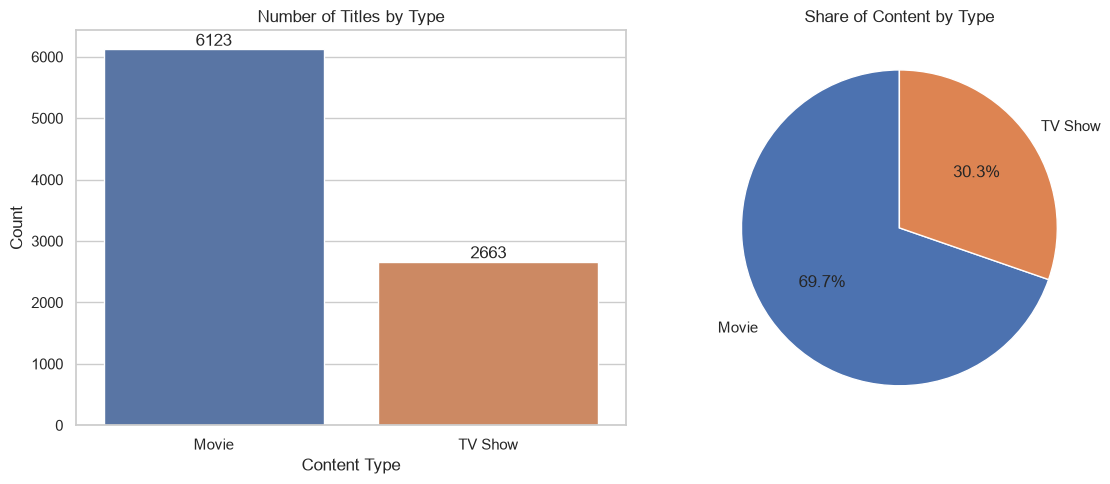

In [48]:
fig,ax=plt.subplots(1,2,figsize=(12,5))

sns.countplot(data=clean_netflix_data ,x='type',hue='type',order=counts.index,ax=ax[0],legend=False)
for c in ax[0].containers:
    ax[0].bar_label(c)
ax[0].set_title('Number of Titles by Type')
ax[0].set_xlabel('Content Type')
ax[0].set_ylabel('Count')

ax[1].pie(counts,labels=counts.index,autopct='%1.1f%%',startangle=90)
ax[1].set_title('Share of Content by Type')

plt.tight_layout()
plt.savefig('task2_distribution.png',dpi=150)
plt.show()

- Step 4: Compare content proportions

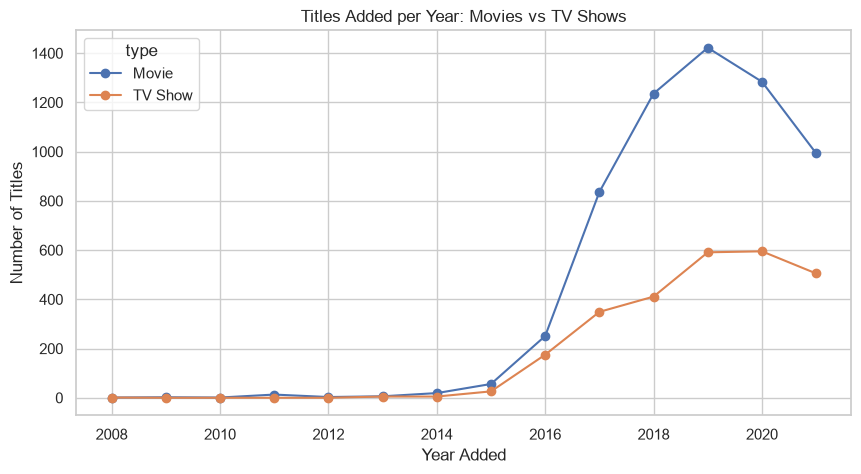

In [49]:
# (a) How the mix changed by the year content was added to Netflix
by_year=clean_netflix_data.groupby(['year_added','type']).size().unstack(fill_value=0)
by_year.plot(kind='line', marker='o', figsize=(10,5))
plt.title('Titles Added per Year: Movies vs TV Shows')
plt.xlabel('Year Added'); plt.ylabel('Number of Titles')
plt.savefig('task2_by_year.png',dpi=150)
plt.show()

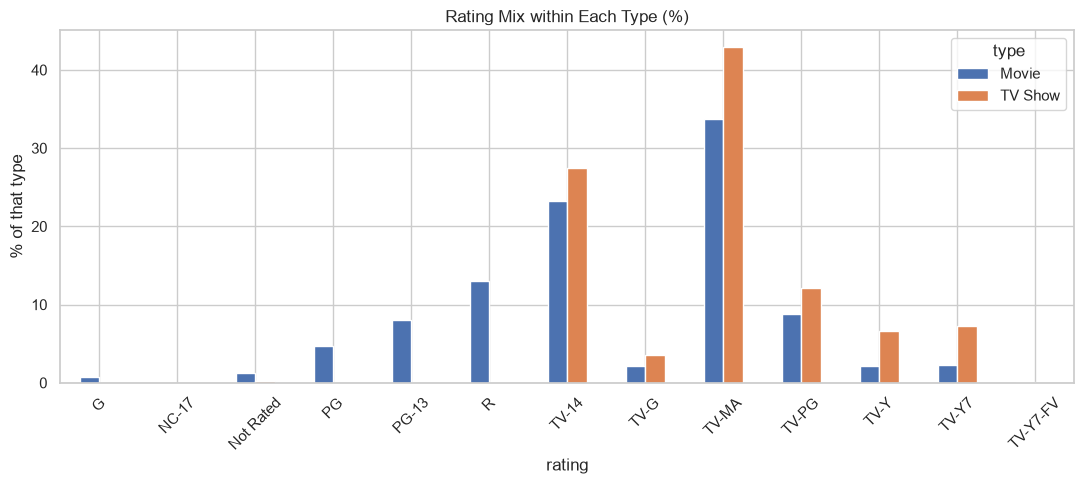

In [50]:
# (b) Rating mix inside each type (each column sums to 100%)
rating_mix=pd.crosstab(clean_netflix_data['rating'],clean_netflix_data['type'],normalize='columns') * 100
rating_mix.round(1).plot(kind='bar',figsize=(11,5))
plt.title('Rating Mix within Each Type (%)')
plt.ylabel('% of that type')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('task2_rating_mix.png',dpi=150)
plt.show()

In [51]:
# (c) Typical size of each type
print(clean_netflix_data[clean_netflix_data['type']=='Movie']['duration_value'].describe())   #minutes
print(clean_netflix_data[clean_netflix_data['type']=='TV Show']['duration_value'].value_counts().head()) #seasons

count    6123.000000
mean       99.572595
std        28.282615
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: duration_value, dtype: float64
duration_value
1    1790
2     421
3     198
4      94
5      64
Name: count, dtype: int64


(a) shows whether the Movies-to-TV Shows mix is stable or shifting. 

(b) uses normalize='columns' so each type is judged against itself. Raw counts would only show that Movies are more numerous.

(c) summarizes Movies by minutes and TV Shows by seasons separately, since I
can't compare the two directly (this is why I split duration in Task 1).

- Step 5: Summary of Key Findings

- Overall split: "Movies make up 69.7% and TV Shows 30.3% of the catalogue."
  
- Trend: The line chart shows that Movies peaked at about 1,400 in 2019,  and then fell in 2020 and 2021. Both types were near zero until about 2015 and took off from 2016. TV Shows rose more slowly and peaked at about 600 in 2019 to 2020.

- Ratings: TV-MA (3,204 titles) and TV-14 (2,155 titles) are the top two ratings. Together they cover about 61% of the catalogue.
The kids' ratings (TV-Y, TV-Y7, TV-G) are small slices.
So the audience skews teen and adult, not children.

- Limitation:The 90.6% missing-director figure for TV Shows is why director was not used here.

### Task 3: Country-Wise Netflix Content Analysis

- Step 1: Extract and clean country information

In [52]:
sns.set_theme(style='whitegrid')
clean_netflix_data['country']=clean_netflix_data['country'].str.strip()
print(clean_netflix_data['country'].nunique(),'distinct values')
print((clean_netflix_data['country']=='Unknown').sum(),'rows have no country')

known=clean_netflix_data[clean_netflix_data['country'] !='Unknown'].copy()
print(len(known),'rows kept for country analysis')

86 distinct values
287 rows have no country
8499 rows kept for country analysis


This dataset has exactly one country per row (no commas), so no splitting is needed. The 287 Unknown rows must be excluded here. If we left them in, "Unknown" would rank as the 5th "country" and mislead the chart. 

- Step 2: Calculate content count by country

In [53]:
country_counts=known['country'].value_counts()
print(country_counts.head(15))
print('Countries with only 1 title:', (country_counts==1).sum())

country
United States     3240
India             1056
United Kingdom     638
Pakistan           420
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Egypt              123
Australia          114
Turkey             111
Nigeria            105
Germany            104
Name: count, dtype: int64
Countries with only 1 title: 18


value_counts() is the groupby-and-count in one line. The last line shows how long the tail is: many countries contribute a single title, which is why we rank the top ones.

- Step 3: Identifying top content-producing countries

In [54]:
top10=country_counts.head(10)

share=(top10/len(known)*100).round(1)
ranking=pd.DataFrame({'Titles':top10,'Share %':share})
ranking.insert(0,'Rank',range(1,11))
print(ranking)

print('Top 3 share:',round(country_counts.head(3).sum()/len(known) * 100,1), '%')
print('Top 10 share:', round(top10.sum()/len(known) * 100,1),'%')

                Rank  Titles  Share %
country                              
United States      1    3240     38.1
India              2    1056     12.4
United Kingdom     3     638      7.5
Pakistan           4     420      4.9
Canada             5     271      3.2
Japan              6     259      3.0
South Korea        7     214      2.5
France             8     213      2.5
Spain              9     182      2.1
Mexico            10     138      1.6
Top 3 share: 58.1 %
Top 10 share: 78.0 %


The ranking table is the required "rankings" output. The share columns turn counts into a business statement ("the top 3 countries supply 58.1% of known-country content"), which is what Step 5 asks for

Step 4: Create charts and rankings

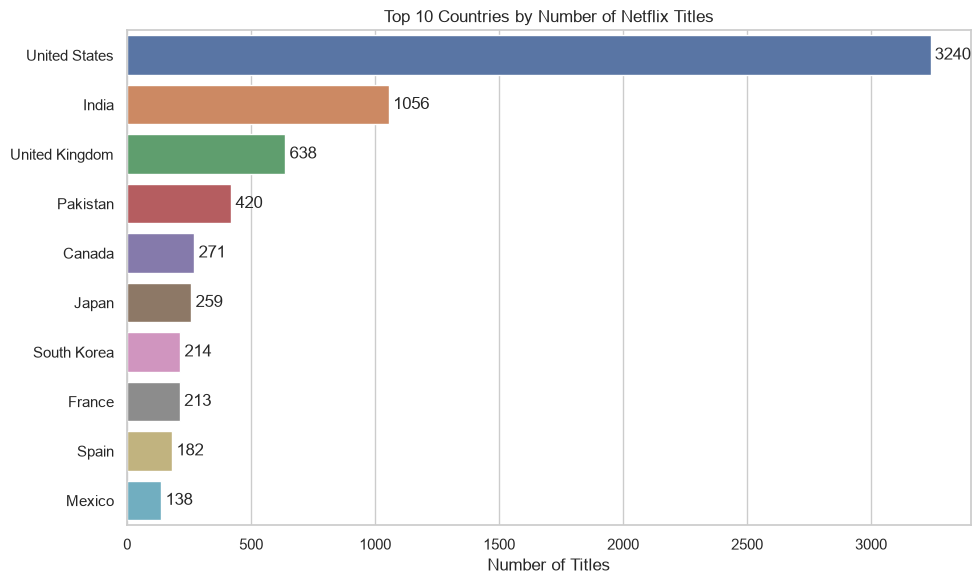

In [55]:
# Chart 1: top 10 countries
plt.figure(figsize=(10,6))
ax=sns.barplot(x=top10.values,y=top10.index,hue=top10.index,legend=False)
for c in ax.containers:
    ax.bar_label(c,padding=3)
plt.title('Top 10 Countries by Number of Netflix Titles')
plt.xlabel('Number of Titles');plt.ylabel('')
plt.tight_layout()
plt.savefig('task3_top10.png',dpi=150)
plt.show()

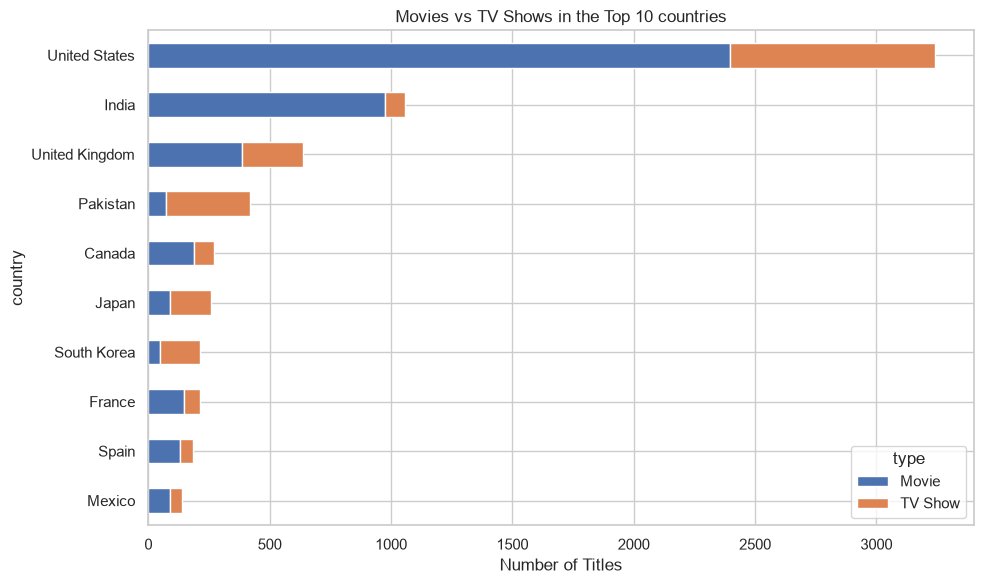

type            Movie  TV Show  TV share %
country                                   
United States    2395      845        26.1
India             975       81         7.7
United Kingdom    387      251        39.3
Pakistan           71      349        83.1
Canada            187       84        31.0
Japan              87      172        66.4
South Korea        49      165        77.1
France            148       65        30.5
Spain             129       53        29.1
Mexico             90       48        34.8


In [56]:
# Chart 2: what each top country produces (Movies vs TV Show)
mix=pd.crosstab(known['country'],known['type']).loc[top10.index]
mix.plot(kind='barh',stacked=True,figsize=(10,6))
plt.gca().invert_yaxis()
plt.title('Movies vs TV Shows in the Top 10 countries')
plt.xlabel('Number of Titles')
plt.tight_layout()
plt.savefig('task3_type_mix.png',dpi=150)
plt.show()

mix['TV share %']=(mix['TV Show']/mix.sum(axis=1) *100).round(1)
print(mix)

Chart 1 answers "who produces the most". Chart 2 answers the follow-up "what kind of content", which is where the real business insight is. The TV share % column puts numbers behind what the chart shows. invert_yaxis() keeps rank 1 at the top so the order matches Chart 1

- Step 5: Generating business insights

- Concentration:
The top 3 countries supply 58.1% of known-country content,while the top 10 countries supply 78.0% of known-country content

- Leaders:
The United States is first and it is ahead of the second place by 25.7 percentage points


- Content mix: 
Countries like  ['Japan','Pakistan','South Korea']  lean heavily toward TV Shows.
Countries like  ['United States','India','United Kingdom','Canada','France','Spain','Mexico']  lean toward Movies.


- Business reading: Netflix could add more TV content in countries like ['Japan','Pakistan','SouthKorea'] and add more Movie Content in countries like  ['United States','India','United Kingdom','Canada','France','Spain','Mexico'].

- Limitation: 287 titles with no country (about 3%) were excluded.

### Task 4: Trend Analysis by Release Year.

Step 1: Organizing content by release year.

In [57]:
print(clean_netflix_data['release_year'].min(),clean_netflix_data['release_year'].max())
print('Released before 2000:', round((clean_netflix_data['release_year']<2000).mean()*100,1),'%')
print('Released since 2010:', round((clean_netflix_data['release_year']>=2010).mean()*100,1),'%')
            

1925 2021
Released before 2000: 6.0 %
Released since 2010: 84.8 %


The data runs from 1925 to 2021,but most of it is recent. Knowing this lets me focus the charts on where the data is.

Step 2: Calculating yearly content releases

In [58]:
yearly=clean_netflix_data.groupby('release_year').size() #titles per release year
recent=yearly.loc[2000:]   # focus on 2000 onward

print(recent.tail(10))
print('Peak year:',recent.idxmax(),'with',recent.max(),'titles')

release_year
2012     236
2013     286
2014     351
2015     555
2016     901
2017    1030
2018    1144
2019    1029
2020     953
2021     592
dtype: int64
Peak year: 2018 with 1144 titles


groupby('release_year').size() counts titles per year. Cutting at 2000 avoids a long flat line for the 1920s to 1990s, which would squash the part that matters. 

Step 3: Identify growth and decline trends

In [59]:
growth=pd.DataFrame({
    'Titles':recent,
    'Change':recent.diff(),                      #difference vs previous year 
    'YoY %': (recent.pct_change() *100).round(1),  #percent change vs previous year
    '3-yr avg': recent.rolling(3).mean().round(0)   # smooths out year-to-year noise
})
print(growth.tail(10))

print('Biggest jump:', growth['Change'].idxmax(),'|',growth['Change'].max(),'titles')
print('Biggest drop:', growth['Change'].idxmin(), '|', growth['Change'].min(),'titles')

              Titles  Change  YoY %  3-yr avg
release_year                                 
2012             236    51.0   27.6     204.0
2013             286    50.0   21.2     236.0
2014             351    65.0   22.7     291.0
2015             555   204.0   58.1     397.0
2016             901   346.0   62.3     602.0
2017            1030   129.0   14.3     829.0
2018            1144   114.0   11.1    1025.0
2019            1029  -115.0  -10.1    1068.0
2020             953   -76.0   -7.4    1042.0
2021             592  -361.0  -37.9     858.0
Biggest jump: 2016 | 346.0 titles
Biggest drop: 2021 | -361.0 titles


The count tells me the level; diff() and pct_change() tell me the direction and speed. The rolling average shows the real trend by smoothing single-year spikes. The biggest-jump and biggest-drop lines directly answer "identify growth and decline".

Step 4: Create trend visualisations:

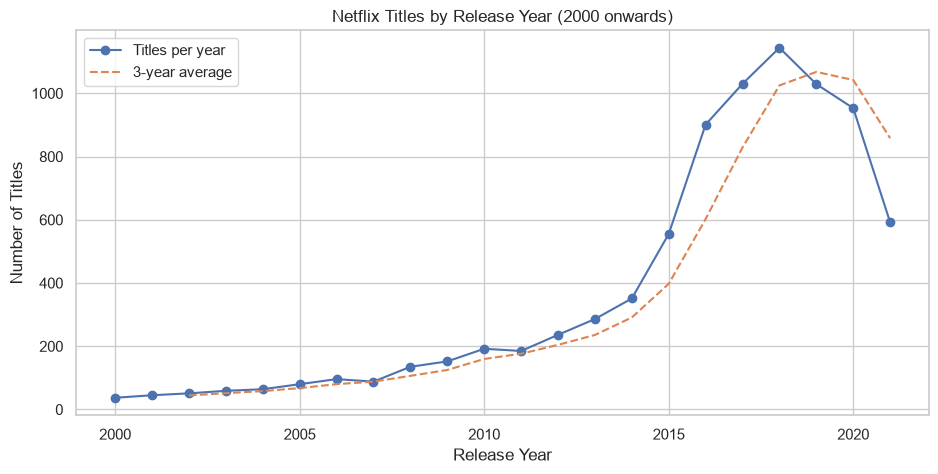

In [60]:
# Chart 1: overall yearly trend
plt.figure(figsize=(11,5))
plt.plot(recent.index,recent.values,marker='o',label='Titles per year')
plt.plot(recent.index,recent.rolling(3).mean(),linestyle='--',label='3-year average')
plt.title('Netflix Titles by Release Year (2000 onwards)')
plt.xlabel('Release Year'); plt.ylabel('Number of Titles')
plt.legend()
plt.savefig('task_overall.png',dpi=150)
plt.show()

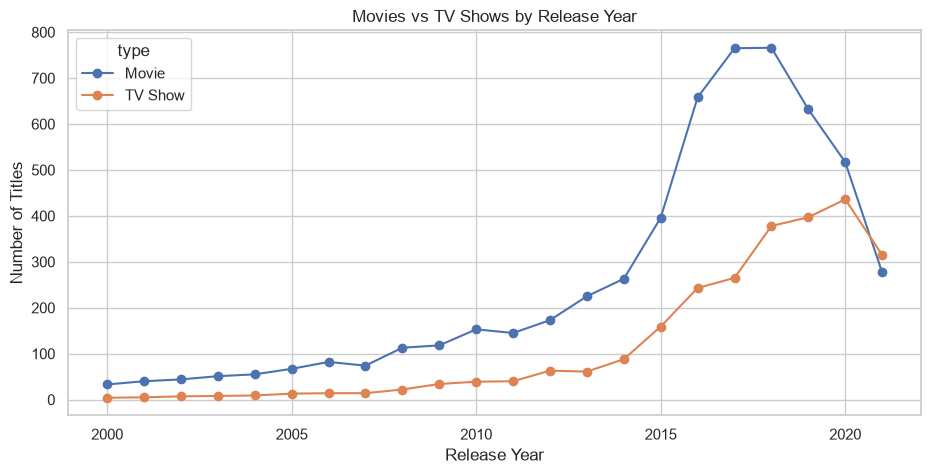

type
Movie      2018
TV Show    2020
dtype: int64


In [61]:
# Chart 2: Movies vs TV Shows by release year
by_type=clean_netflix_data.groupby(['release_year','type']).size().unstack(fill_value=0).loc[2000:]
by_type.plot(figsize=(11,5),marker='o')
plt.title('Movies vs TV Shows by Release Year')
plt.xlabel('Release Year'); plt.ylabel('Number of Titles')
plt.savefig('task4_by_type.png',dpi=150)
plt.show()

print(by_type.idxmax()) #peak year for each type

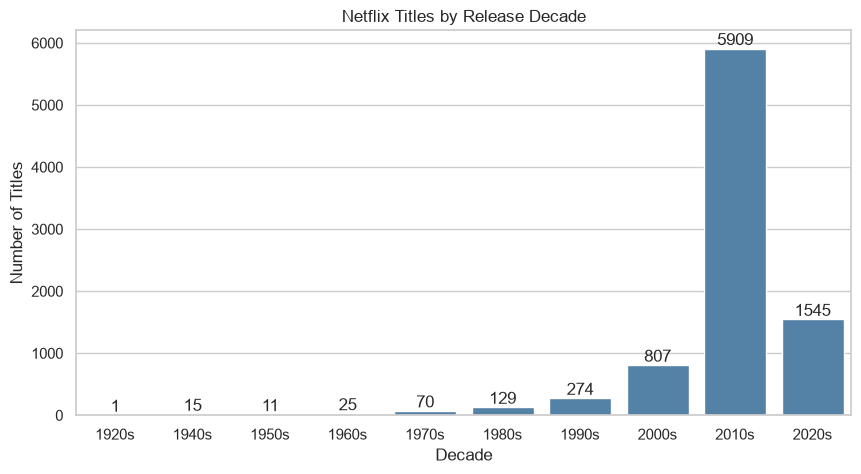

In [62]:
# Chart 3: Titles by decade
clean_netflix_data['decade']=(clean_netflix_data['release_year']// 10) * 10
decade_counts=clean_netflix_data['decade'].value_counts().sort_index()

plt.figure(figsize=(10,5))
ax=sns.barplot(x=decade_counts.index.astype(str) + 's', y=decade_counts.values,color='steelblue')
for c in ax.containers:
    ax.bar_label(c)
plt.title('Netflix Titles by Release Decade')
plt.xlabel('Decade');plt.ylabel('Number of Titles')
plt.savefig('task4_decades.png',dpi=150)
plt.show()

Chart 1 is the main trend. Chart 2 asks whether Movies and TV Shows follow the same pattern. Chart 3 sums the story up by decade, because // 10 * 10 rounds each year down to its decade (for example 2017 becomes 2010). Run by_type.idxmax() and note the peak year for each type, because the peaks differ

Step 5: Interpret business patterns

### Step 5: Interpret business patterns

- **Where the content is:** 84.8% of titles were released since 2010, and only 6.0% before 2000. The catalogue is heavily weighted toward recent content.

- **Peak:** 2018 is the peak release year, with 1,144 titles.

- **Growth phase:** 2016 shows the biggest jump, with 346 extra titles (901 against 555 in 2015). Growth then slowed: YoY growth fell from 62.3% in 2016 to 14.3% in 2017 and 11.1% in 2018. Releases were still rising, but more slowly each year until the 2018 peak.

- **Decline:** After the 2018 peak, releases fell to 1,029 in 2019 (-10.1%) and 953 in 2020 (-7.4%). The 2021 figure (592 titles, -37.9%) should not be read as a real collapse, because the dataset ends in September 2021 and that year is incomplete.

- **Movies vs TV Shows:** Movies peak in 2018 (766 titles) and TV Shows peak later, in 2020 (436 titles). Movie releases fall steadily after 2018, while TV releases keep growing for two more years. This suggests Netflix's focus moved toward series over this period, although the 2021 numbers are partial and should be read with caution.

- **Limitation:** This counts titles by release year, not by when they were added to Netflix. A film made in 2015 may have joined the catalogue in 2019, so these charts show when content was produced, not when Netflix acquired it. The analysis also covers only 2000 onwards for the trend charts, and the data is a snapshot of the catalogue, so it only shows titles that were available when it was collected.